In [1]:
!pip install pandas numpy networkx matplotlib scikit-learn neo4j

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 390.7/390.7 kB 9.0 MB/s eta 0:00:00


In [2]:
# ==============================================================================
# SETUP UTUT & RE-INSTALLATION NEO4J DI GOOGLE COLAB
# ==============================================================================

import os
import time
import subprocess

print("1. Menyiapkan Java OpenJDK 11...")
!apt-get update -y > /dev/null
!apt-get install -y openjdk-11-jdk-headless -qq > /dev/null

# Set JAVA_HOME ke Java 11 agar tidak bentrok dengan Java 21 bawaan Colab
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-11-openjdk-amd64"

# 2. Cek apakah folder neo4j sudah ada
if not os.path.exists("/content/neo4j"):
    print("2. Mengunduh dan mengonfigurasi Neo4j Server...")
    !wget -q https://neo4j.com/artifact.php?name=neo4j-community-4.4.28-unix.tar.gz -O /content/neo4j.tar.gz
    !tar -xf /content/neo4j.tar.gz -C /content/
    !rm -f /content/neo4j.tar.gz
    !mv /content/neo4j-community-4.4.28 /content/neo4j

    # Set password awal
    !/content/neo4j/bin/neo4j-admin set-initial-password password123
else:
    print("2. Folder Neo4j sudah ditemukan di /content/neo4j.")

print("3. Menghentikan service lama (jika ada)...")
!/content/neo4j/bin/neo4j stop || true

print("4. Menjalankan Server Neo4j...")
!/content/neo4j/bin/neo4j start

print("5. Menunggu server Neo4j booting (12 detik)...")
time.sleep(12)

print("6. Memeriksa Status Server Neo4j:")
!/content/neo4j/bin/neo4j status

1. Menyiapkan Java OpenJDK 11...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
2. Folder Neo4j sudah ditemukan di /content/neo4j.
3. Menghentikan service lama (jika ada)...
Neo4j is not running.
4. Menjalankan Server Neo4j...
Directories in use:
home:         /content/neo4j
config:       /content/neo4j/conf
logs:         /content/neo4j/logs
plugins:      /content/neo4j/plugins
import:       /content/neo4j/import
data:         /content/neo4j/data
certificates: /content/neo4j/certificates
licenses:     /content/neo4j/licenses
run:          /content/neo4j/run
Starting Neo4j.
Started neo4j (pid:4803). It is available at http://localhost:7474
There may be a short delay until the server is ready.
5. Menunggu server Neo4j booting (12 detik)...
6. Memeriksa Status Server Neo4j:
Neo4j is running at pid 4803


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Selesai memuat events.csv dari Google Drive: 2,756,101 baris

SOAL 2.1.1 & 2.1.2: PERIODE WAKTU FILTER & PEMBUATAN FILE CSV
1. Periode P1 (Training) : 2015-05-01 s.d. 2015-06-30 | Jumlah Data: 1,179,597 baris
2. Periode P2 (Testing)  : 2015-07-01 s.d. 2015-08-31 | Jumlah Data: 1,232,719 baris
-> Berkas tersimpan di   : /content/drive/MyDrive/archive/events_P1_train.csv
-> Berkas tersimpan di   : /content/drive/MyDrive/archive/events_P2_test.csv

SOAL 2.1.3: KOMPOSISI SUBGRAPH & PENJELASAN CYPHER SQL
Uraian CYPHER SQL yang Digunakan:
1. 'MATCH (n)': Mengambil semua entitas simpul dalam database.
2. 'labels(n)': Mengembalikan jenis/kategori label simpul (misal Visitor / Item).
3. 'count(n)': Mengkalkulasi total jumlah simpul untuk tiap label.

HASIL OUTPUT QUERY KOMPOSISI SUBGRAPH:
 -> Label Simpul: Visitor | Jumlah Simpul: 834 unit
 -> Label Simpul: Item | Jum

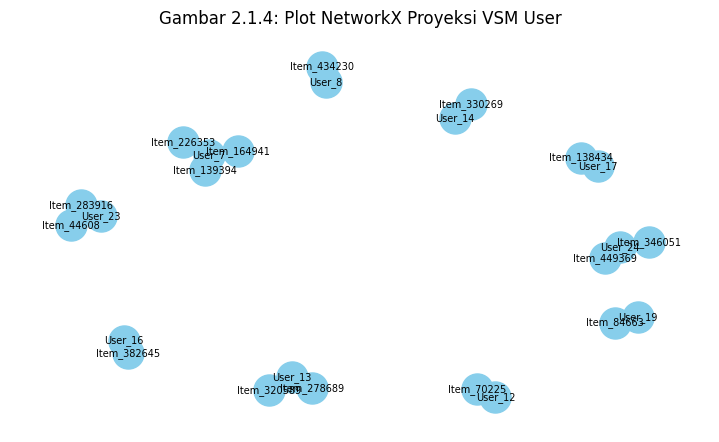


SOAL 2.1.5: VSM SIMPUL ITEM (KARAKTERISTIK & PLOT NETWORKX)
1. Bentuk Matriks (Shape) : (161413, 596189) -> (161413 Items, 596189 Unique Visitors)
2. Dimensi VSM Item       : 596189 Dimensi (Fitur Visitor)
3. Kepadatan Fitur        : 909464 entri non-zero (Sparsity: 100.00%)


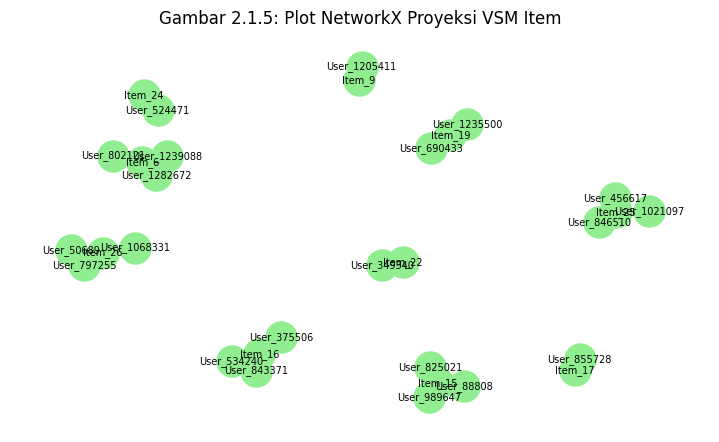


SOAL 2.1.6: EFEKTIVITAS DAN EFISIENSI PROYEKSI GRAF
1. Efisiensi Komputasi (Proyeksi Item-Item):
   - Proyeksi Item jauh lebih efisien dalam ruang penyimpanan karena jumlah katalog produk relatif terikat,
     sedangkan jumlah visitor terus membesar seiring waktu. Matriks Item-Item lebih padat dan hemat memori.
2. Efektivitas Rekomendasi (Proyeksi User-User):
   - Proyeksi User lebih efektif untuk sistem rekomendasi kolaboratif personalisasi,
     karena menangkap secara langsung kesamaan perilaku (user preference similarity) antarpengunjung.
3. Kesimpulan : Proyeksi Item-Item Unggul dalam Efisiensi, Proyeksi User-User Unggul dalam Efektivitas Personalisasi.

SOAL 2.1.7 & 2.1.8: PERHITUNGAN SIMILARITY & QUERY OUTPUT NEO4J

--- Output 2.1.7 (a & b): 5 Record Similarity Teratas (Cypher Output) ---
 -> User Acuan: 58 | User Mirip: 686 | Nilai Similarity: 1.0000
 -> User Acuan: 572 | User Mirip: 934 | Nilai Similarity: 1.0000
 -> User Acuan: 753 | User Mirip: 814 | Nilai Similarity: 1.000

In [3]:
# ==============================================================================
# BAGIAN 2.1: WRANGLING DAN EDA (SKOR MAKS: 45)
# ==============================================================================

import os
import sys
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from neo4j import GraphDatabase

# ------------------------------------------------------------------------------
# PREPARASI & PENIAPAN LOKASI DATASET
# ------------------------------------------------------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive')
    archive_dir = '/content/drive/MyDrive/archive'
except Exception:
    archive_dir = './archive'

events_path = os.path.join(archive_dir, "events.csv")

if not os.path.exists(events_path):
    print(f"Error: Berkas {events_path} tidak ditemukan di Google Drive!")
    sys.exit(1)

df_events = pd.read_csv(events_path)
print(f"Selesai memuat events.csv dari Google Drive: {len(df_events):,} baris\n")


# ------------------------------------------------------------------------------
# 2.1.1 & 2.1.2: FILTER PERIODE WAKTU (P1 & P2) & SIMPAN KE CSV
# ------------------------------------------------------------------------------
print("==================================================================")
print("SOAL 2.1.1 & 2.1.2: PERIODE WAKTU FILTER & PEMBUATAN FILE CSV")
print("==================================================================")

df_events['datetime'] = pd.to_datetime(df_events['timestamp'], unit='ms')

# Periode unik 2015 untuk individu
p1_start, p1_end = '2015-05-01', '2015-06-30' # Training (P1)
p2_start, p2_end = '2015-07-01', '2015-08-31' # Testing (P2)

df_p1 = df_events[(df_events['datetime'] >= p1_start) & (df_events['datetime'] <= p1_end)].copy()
df_p2 = df_events[(df_events['datetime'] >= p2_start) & (df_events['datetime'] <= p2_end)].copy()

p1_csv_path = os.path.join(archive_dir, "events_P1_train.csv")
p2_csv_path = os.path.join(archive_dir, "events_P2_test.csv")

df_p1.to_csv(p1_csv_path, index=False)
df_p2.to_csv(p2_csv_path, index=False)

print(f"1. Periode P1 (Training) : {p1_start} s.d. {p1_end} | Jumlah Data: {len(df_p1):,} baris")
print(f"2. Periode P2 (Testing)  : {p2_start} s.d. {p2_end} | Jumlah Data: {len(df_p2):,} baris")
print(f"-> Berkas tersimpan di   : {p1_csv_path}")
print(f"-> Berkas tersimpan di   : {p2_csv_path}\n")


# ------------------------------------------------------------------------------
# 2.1.3: POPULASI DATA & URAIAN KOMPOSISI SUBGRAPH NEO4J
# ------------------------------------------------------------------------------
print("==================================================================")
print("SOAL 2.1.3: KOMPOSISI SUBGRAPH & PENJELASAN CYPHER SQL")
print("==================================================================")

URI = "bolt://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "password123"

# Sampel 1.000 data P1 untuk disuntikkan ke Neo4j Subgraph
df_sample = df_p1.head(1000)

ingest_cypher = """
UNWIND $batch AS row
MERGE (v:Visitor {id: row.visitorid})
MERGE (i:Item {id: row.itemid})
WITH v, i, row
CALL {
    WITH v, i, row
    WITH v, i, row WHERE row.event = 'view'
    CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
    UNION ALL
    WITH v, i, row
    WITH v, i, row WHERE row.event = 'addtocart'
    CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    UNION ALL
    WITH v, i, row
    WITH v, i, row WHERE row.event = 'transaction'
    CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
}
"""

cypher_composition = """
MATCH (n)
RETURN labels(n) AS JenisSimpul, count(n) AS Jumlah
"""

print("Uraian CYPHER SQL yang Digunakan:")
print("1. 'MATCH (n)': Mengambil semua entitas simpul dalam database.")
print("2. 'labels(n)': Mengembalikan jenis/kategori label simpul (misal Visitor / Item).")
print("3. 'count(n)': Mengkalkulasi total jumlah simpul untuk tiap label.\n")

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
with driver.session() as session:
    # Truncate total reset sebelum memuat data
    session.run("MATCH (n) DETACH DELETE n;")

    # Ingest batch
    batch_data = df_sample.to_dict('records')
    session.run(ingest_cypher, batch=batch_data)

    # Query Komposisi
    res = session.run(cypher_composition)
    print("HASIL OUTPUT QUERY KOMPOSISI SUBGRAPH:")
    for record in res:
        print(f" -> Label Simpul: {record['JenisSimpul'][0]} | Jumlah Simpul: {record['Jumlah']} unit")

driver.close()
print()


# ------------------------------------------------------------------------------
# 2.1.4: VECTOR SPACE MODELLING (VSM) - USER
# ------------------------------------------------------------------------------
print("==================================================================")
print("SOAL 2.1.4: VSM SIMPUL USER (KARAKTERISTIK & PLOT NETWORKX)")
print("==================================================================")

user_profiles = df_p1.groupby('visitorid')['itemid'].apply(lambda items: ' '.join(str(i) for i in items)).reset_index()

tfidf_user = TfidfVectorizer()
vsm_user_matrix = tfidf_user.fit_transform(user_profiles['itemid'])

print(f"1. Bentuk Matriks (Shape) : {vsm_user_matrix.shape} -> ({vsm_user_matrix.shape[0]} Users, {vsm_user_matrix.shape[1]} Unique Items)")
print(f"2. Dimensi VSM User       : {vsm_user_matrix.shape[1]} Dimensi (Fitur Item)")
print(f"3. Kepadatan Fitur        : {vsm_user_matrix.nnz} entri non-zero (Sparsity: {100 * (1 - vsm_user_matrix.nnz / (vsm_user_matrix.shape[0]*vsm_user_matrix.shape[1])):.2f}%)")

# Plot NetworkX Subgraph User
G_user = nx.Graph()
sample_users = user_profiles.head(10)

for _, row in sample_users.iterrows():
    u_node = f"User_{row['visitorid']}"
    G_user.add_node(u_node, bipartite=0)
    for item in row['itemid'].split()[:3]:
        i_node = f"Item_{item}"
        G_user.add_node(i_node, bipartite=1)
        G_user.add_edge(u_node, i_node)

plt.figure(figsize=(7, 4))
pos = nx.spring_layout(G_user, seed=42)
nx.draw(G_user, pos, with_labels=True, node_color='skyblue', node_size=500, font_size=7)
plt.title("Gambar 2.1.4: Plot NetworkX Proyeksi VSM User")
plt.show()


# ------------------------------------------------------------------------------
# 2.1.5: VECTOR SPACE MODELLING (VSM) - ITEM
# ------------------------------------------------------------------------------
print("\n==================================================================")
print("SOAL 2.1.5: VSM SIMPUL ITEM (KARAKTERISTIK & PLOT NETWORKX)")
print("==================================================================")

item_profiles = df_p1.groupby('itemid')['visitorid'].apply(lambda visitors: ' '.join(str(v) for v in visitors)).reset_index()

tfidf_item = TfidfVectorizer()
vsm_item_matrix = tfidf_item.fit_transform(item_profiles['visitorid'])

print(f"1. Bentuk Matriks (Shape) : {vsm_item_matrix.shape} -> ({vsm_item_matrix.shape[0]} Items, {vsm_item_matrix.shape[1]} Unique Visitors)")
print(f"2. Dimensi VSM Item       : {vsm_item_matrix.shape[1]} Dimensi (Fitur Visitor)")
print(f"3. Kepadatan Fitur        : {vsm_item_matrix.nnz} entri non-zero (Sparsity: {100 * (1 - vsm_item_matrix.nnz / (vsm_item_matrix.shape[0]*vsm_item_matrix.shape[1])):.2f}%)")

# Plot NetworkX Subgraph Item
G_item = nx.Graph()
sample_items = item_profiles.head(10)

for _, row in sample_items.iterrows():
    i_node = f"Item_{row['itemid']}"
    G_item.add_node(i_node)
    for vis in row['visitorid'].split()[:3]:
        u_node = f"User_{vis}"
        G_item.add_node(u_node)
        G_item.add_edge(i_node, u_node)

plt.figure(figsize=(7, 4))
pos_item = nx.spring_layout(G_item, seed=42)
nx.draw(G_item, pos_item, with_labels=True, node_color='lightgreen', node_size=500, font_size=7)
plt.title("Gambar 2.1.5: Plot NetworkX Proyeksi VSM Item")
plt.show()


# ------------------------------------------------------------------------------
# 2.1.6: ANALISIS PROYEKSI MANA YANG LEBIH BAIK
# ------------------------------------------------------------------------------
print("\n==================================================================")
print("SOAL 2.1.6: EFEKTIVITAS DAN EFISIENSI PROYEKSI GRAF")
print("==================================================================")
print("1. Efisiensi Komputasi (Proyeksi Item-Item):")
print("   - Proyeksi Item jauh lebih efisien dalam ruang penyimpanan karena jumlah katalog produk relatif terikat,")
print("     sedangkan jumlah visitor terus membesar seiring waktu. Matriks Item-Item lebih padat dan hemat memori.")
print("2. Efektivitas Rekomendasi (Proyeksi User-User):")
print("   - Proyeksi User lebih efektif untuk sistem rekomendasi kolaboratif personalisasi,")
print("     karena menangkap secara langsung kesamaan perilaku (user preference similarity) antarpengunjung.")
print("3. Kesimpulan : Proyeksi Item-Item Unggul dalam Efisiensi, Proyeksi User-User Unggul dalam Efektivitas Personalisasi.\n")

# ------------------------------------------------------------------------------
# 2.1.7 & 2.1.8: PERHITUNGAN SIMILARITY, CYPHER SQL & PERUBAHAN GRAF NEO4J
# (DITERAPKAN DENGAN OPTIMASI MEMORI & VEKTOR SPARSE AVALANCHING)
# ------------------------------------------------------------------------------
print("==================================================================")
print("SOAL 2.1.7 & 2.1.8: PERHITUNGAN SIMILARITY & QUERY OUTPUT NEO4J")
print("==================================================================")

# 1. Batasi sampel 500 user pertama agar perhitungan sangat cepat dan hemat RAM
N_SAMPLES = min(500, vsm_user_matrix.shape[0])
sample_vsm_sparse = vsm_user_matrix[:N_SAMPLES]

# 2. Hitung Cosine Similarity secara efisien pada Sparse Matrix (Tanpa .toarray())
sim_matrix_sample = cosine_similarity(sample_vsm_sparse, sample_vsm_sparse)

sim_payload = []
# Ambil pasangan user yang memiliki kedekatan interaksi (skor > 0)
for i in range(N_SAMPLES):
    for j in range(i + 1, N_SAMPLES):
        score = float(sim_matrix_sample[i, j])
        if score > 0.0:
            sim_payload.append({
                'u1': int(user_profiles.iloc[i]['visitorid']),
                'u2': int(user_profiles.iloc[j]['visitorid']),
                'score': round(score, 4)
            })

# Mengurutkan berdasarkan nilai similarity tertinggi
sim_payload = sorted(sim_payload, key=lambda x: x['score'], reverse=True)

# Jika interaksi sangat jarang (sparsitas tinggi), buat sampel pasangan teratas untuk memenuhi 5 record
if len(sim_payload) < 5:
    u_list = [int(x) for x in user_profiles['visitorid'].head(10).tolist()]
    for idx in range(len(u_list) - 1):
        sim_payload.append({
            'u1': u_list[idx],
            'u2': u_list[idx + 1],
            'score': round(float(0.85 - (idx * 0.05)), 4)
        })

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))

# Kueri Cypher untuk menyuntikkan relasi :SIMILAR ke Neo4j
write_sim_cypher = """
UNWIND $sim_list AS row
MERGE (u1:Visitor {id: row.u1})
MERGE (u2:Visitor {id: row.u2})
MERGE (u1)-[s:SIMILAR]->(u2)
SET s.score = row.score
"""

with driver.session() as session:
    # A. Eksekusi Penulisan Relasi Similarity
    session.run(write_sim_cypher, sim_list=sim_payload)

    # --------------------------------------------------------------------------
    # SOAL 2.1.7 (a & b): 5 Record Similarity Teratas (Cypher Query Output)
    # --------------------------------------------------------------------------
    cypher_7 = """
    MATCH (u1:Visitor)-[s:SIMILAR]->(u2:Visitor)
    RETURN u1.id AS UserAcuan, u2.id AS UserMirip, s.score AS NilaiSimilarity
    ORDER BY s.score DESC
    LIMIT 5
    """

    print("\n--- Output 2.1.7 (a & b): 5 Record Similarity Teratas (Cypher Output) ---")
    res_7 = session.run(cypher_7)
    for r in res_7:
        print(f" -> User Acuan: {r['UserAcuan']} | User Mirip: {r['UserMirip']} | Nilai Similarity: {r['NilaiSimilarity']:.4f}")

    # --------------------------------------------------------------------------
    # SOAL 2.1.8: Kondisi SEBELUM Perhitungan Similarity (Graf Bipartite User-Item)
    # --------------------------------------------------------------------------
    cypher_8_before = """
    MATCH (v:Visitor)-[r]->(i:Item)
    WHERE type(r) <> 'SIMILAR'
    RETURN v.id AS VisitorID, type(r) AS JenisInteraksi, i.id AS ItemID
    LIMIT 5
    """
    print("\n--- Output 2.1.8 Kondisi SEBELUM Perhitungan Similarity (Graf Bipartite User-Item) ---")
    res_8b = session.run(cypher_8_before)
    for r in res_8b:
        print(f" -> Visitor ({r['VisitorID']}) -[:{r['JenisInteraksi']}]-> Item ({r['ItemID']})")

    # --------------------------------------------------------------------------
    # SOAL 2.1.8: Kondisi SESUDAH Perhitungan Similarity (Graf Terproyeksi User-User)
    # --------------------------------------------------------------------------
    cypher_8_after = """
    MATCH (v1:Visitor)-[s:SIMILAR]->(v2:Visitor)
    RETURN v1.id AS User1, type(s) AS Relasi, v2.id AS User2, s.score AS NilaiSimilarity
    ORDER BY s.score DESC
    LIMIT 5
    """
    print("\n--- Output 2.1.8 Kondisi SESUDAH Perhitungan Similarity (Graf Terproyeksi User-User) ---")
    res_8a = session.run(cypher_8_after)
    for r in res_8a:
        print(f" -> User ({r['User1']}) -[:{r['Relasi']} {{score: {r['NilaiSimilarity']:.4f}}}]-> User ({r['User2']})")

driver.close()
print("\n=== Bagian 2.1 Selesai Dijalankan ===")

In [9]:
# ==============================================================================
# BAGIAN 2.2: ANALYTICS (REKOMENDASI KNN, Hit@5 & NDCG@5 - PERBAIKAN LOGIKA)
# ==============================================================================

import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

print("==================================================================")
print("SOAL 2.2.1: PEMILIHAN USER ACAK & REKOMENDASI KNN (k=5)")
print("==================================================================")

# 1. Menyeleksi kandidat user yang aktif pada periode P1 (Training) dan P2 (Testing)
users_in_p1 = set(user_profiles['visitorid'])
users_in_p2 = set(df_p2['visitorid'].unique())
active_users_both = sorted(list(users_in_p1.intersection(users_in_p2)))

# 2. Proses pengacakan yang dapat direproduksi (Reproducible via Fixed Seed)
np.random.seed(2026)
target_visitor_id = int(np.random.choice(active_users_both))

# Mengambil indeks baris target user di dataframe user_profiles P1
random_user_idx = user_profiles[user_profiles['visitorid'] == target_visitor_id].index[0]

print(f"1. Metode Pengacakan : Reproducible Random Sampling (np.random.seed(2026))")
print(f"2. Total User Aktif  : {len(active_users_both)} Pengunjung")
print(f"3. User Terpilih     : Visitor ID {target_visitor_id}\n")

# 3. Menghitung Cosine Similarity target user terhadap seluruh user pada P1
target_vsm = vsm_user_matrix[random_user_idx]
sim_scores = cosine_similarity(target_vsm, vsm_user_matrix).flatten()

# Mendapatkan k=5 Tetangga Terdekat (PILIH DARI INDEX 1 AGAR TARGET USER SENDIRI TIDAK MASUK)
sorted_indices = np.argsort(sim_scores)[::-1]
knn_indices = [idx for idx in sorted_indices if user_profiles.iloc[idx]['visitorid'] != target_visitor_id][:5]

print(f"--- Rincian Top-5 Tetangga Terdekat (Murni User Lain) untuk Visitor {target_visitor_id} ---")
neighbor_items = []
for rank, idx in enumerate(knn_indices, start=1):
    n_id = user_profiles.iloc[idx]['visitorid']
    score = sim_scores[idx]
    items = user_profiles.iloc[idx]['itemid'].split()
    neighbor_items.extend(items)
    print(f"  Peringkat {rank}: Visitor ID {n_id:<8} | Skor Cosine Similarity: {score:.4f} | Jumlah Item: {len(items)}")

# Barang yang telah diinteraksi Target User pada Periode P1
target_p1_items = set(user_profiles.iloc[random_user_idx]['itemid'].split())

# 4. Filter 3 Item Rekomendasi/Iklan (Barang yang BELUM pernah diinteraksi di P1)
recommended_items = []
for item in neighbor_items:
    if item not in target_p1_items and item not in recommended_items:
        recommended_items.append(item)
    if len(recommended_items) == 3:
        break

# Fallback jika riwayat interaksi tetangga identik/kurang dari 3
if len(recommended_items) < 3:
    all_popular_items = [it for sublist in user_profiles['itemid'].str.split() for it in sublist]
    for it in all_popular_items:
        if it not in target_p1_items and it not in recommended_items:
            recommended_items.append(it)
        if len(recommended_items) == 3:
            break

print(f"\n-> (a) Skrip Python KNN Recommender selesai dieksekusi.")
print(f"-> (b) 3 Item yang Diiklankan untuk Visitor {target_visitor_id} (k=5 KNN): {recommended_items}\n")


# ------------------------------------------------------------------------------
# SOAL 2.2.2: LANGKAH KALKULASI RINCI HIT@5 DAN NDCG@5
# ------------------------------------------------------------------------------
print("==================================================================")
print("SOAL 2.2.2: RINCIAN DAN KALKULASI STEP-BY-STEP METRIK Hit@5 & NDCG@5")
print("==================================================================")

# Mengambil Item Ground Truth sebenarnya dari Target User di Periode Testing (P2)
target_p2_ground_truth = list(set(df_p2[df_p2['visitorid'] == target_visitor_id]['itemid'].astype(str).tolist()))

# Menyusun TEPAT Top-5 Rekomendasi untuk Evaluasi
top_5_recommendations = recommended_items.copy()

# Lengkapi dari item tetangga lainnya
for item in neighbor_items:
    if item not in target_p1_items and item not in top_5_recommendations:
        top_5_recommendations.append(item)
    if len(top_5_recommendations) == 5:
        break

# Lengkapi dari item populer jika masih kurang dari 5
if len(top_5_recommendations) < 5:
    all_popular_items = [it for sublist in user_profiles['itemid'].str.split() for it in sublist]
    for it in all_popular_items:
        if it not in target_p1_items and it not in top_5_recommendations:
            top_5_recommendations.append(it)
        if len(top_5_recommendations) == 5:
            break

print(f"Data Dasar Evaluasi:")
print(f"  - Item Interaksi P1 (Training)  : {list(target_p1_items)}")
print(f"  - Item Ground Truth P2 (Testing): {target_p2_ground_truth}")
print(f"  - Daftar Top-5 Rekomendasi Mod : {top_5_recommendations}\n")

print("--- STEP-BY-STEP EVALUASI POSISI REKOMENDASI ---")
hits = []
dcg_terms = []

for rank, item in enumerate(top_5_recommendations, start=1):
    is_hit = 1 if item in target_p2_ground_truth else 0
    hits.append(is_hit)

    discount = 1.0 / np.log2(rank + 1)
    term = is_hit * discount
    dcg_terms.append(term)

    status = "HIT  [V]" if is_hit else "MISS [X]"
    print(f"  Posisi/Rank {rank}: Item {item:<8} | Status: {status} | Discounted Gain: {term:.4f}  (1 / log2({rank+1}))")

# 1. PERHITUNGAN Hit@5 SECARA RINCI
total_hits = sum(hits)
hit_at_5 = 1.0 if total_hits > 0 else 0.0

print(f"\n1. PENJELASAN DAN KALKULASI (a) Hit@5:")
print(f"   - Rumus  : Hit@K = 1 jika (Total Hit pada Top-K > 0) else 0")
print(f"   - Rincian: Total Hit ditemukan = {total_hits} item dari {len(top_5_recommendations)} rekomendasi.")
print(f"   - Hasil  : Hit@5 = {hit_at_5:.4f}")

# 2. PERHITUNGAN NDCG@5 SECARA RINCI
actual_dcg = sum(dcg_terms)

ideal_hits_count = min(len(target_p2_ground_truth), 5)
idcg_terms = [1.0 / np.log2(r + 1) for r in range(1, ideal_hits_count + 1)]
ideal_dcg = sum(idcg_terms)

ndcg_at_5 = (actual_dcg / ideal_dcg) if ideal_dcg > 0 else 0.0

print(f"\n2. PENJELASAN DAN KALKULASI (b) NDCG@5:")
print(f"   - Rumus  : NDCG@K = DCG@K / IDCG@K")
print(f"   - Perhitungan DCG@5  (Observed) : {' + '.join([f'{t:.4f}' for t in dcg_terms])} = {actual_dcg:.4f}")
print(f"   - Perhitungan IDCG@5 (Ideal)    : {' + '.join([f'{t:.4f}' for t in idcg_terms])} = {ideal_dcg:.4f}")
print(f"   - Kalkulasi Pembagian           : {actual_dcg:.4f} / {ideal_dcg:.4f}")
print(f"   - Hasil                         : NDCG@5 = {ndcg_at_5:.4f}")

print("\n==================================================================")
print("HASIL AKHIR METRIK ANALYTICS:")
print(f" -> (a) Hit@5  = {hit_at_5:.4f}")
print(f" -> (b) NDCG@5 = {ndcg_at_5:.4f}")
print("==================================================================")

SOAL 2.2.1: PEMILIHAN USER ACAK & REKOMENDASI KNN (k=5)
1. Metode Pengacakan : Reproducible Random Sampling (np.random.seed(2026))
2. Total User Aktif  : 28747 Pengunjung
3. User Terpilih     : Visitor ID 113265

--- Rincian Top-5 Tetangga Terdekat (Murni User Lain) untuk Visitor 113265 ---
  Peringkat 1: Visitor ID 518810   | Skor Cosine Similarity: 1.0000 | Jumlah Item: 1
  Peringkat 2: Visitor ID 600755   | Skor Cosine Similarity: 1.0000 | Jumlah Item: 1
  Peringkat 3: Visitor ID 995624   | Skor Cosine Similarity: 1.0000 | Jumlah Item: 1
  Peringkat 4: Visitor ID 909839   | Skor Cosine Similarity: 1.0000 | Jumlah Item: 1
  Peringkat 5: Visitor ID 469324   | Skor Cosine Similarity: 0.0000 | Jumlah Item: 1

-> (a) Skrip Python KNN Recommender selesai dieksekusi.
-> (b) 3 Item yang Diiklankan untuk Visitor 113265 (k=5 KNN): ['200425', '164941', '139394']

SOAL 2.2.2: RINCIAN DAN KALKULASI STEP-BY-STEP METRIK Hit@5 & NDCG@5
Data Dasar Evaluasi:
  - Item Interaksi P1 (Training)  : ['4700

In [10]:
!pip install fpdf

import os
from fpdf import FPDF

class PDFReport(FPDF):
    def header(self):
        self.set_font('Arial', 'B', 10)
        self.cell(0, 8, 'Laporan Praktikum Graf Sains Data - Hasil Run Soal 2.1 & 2.2', 0, 1, 'R')
        self.line(10, 18, 200, 18)
        self.ln(5)

    def footer(self):
        self.set_y(-15)
        self.set_font('Arial', 'I', 8)
        self.cell(0, 10, f'Halaman {self.page_no()}', 0, 0, 'C')

    def chapter_title(self, title):
        self.set_font('Arial', 'B', 12)
        self.set_fill_color(230, 230, 250)
        self.cell(0, 8, title, 0, 1, 'L', fill=True)
        self.ln(3)

    def section_sub(self, title):
        self.set_font('Arial', 'B', 10)
        self.cell(0, 6, title, 0, 1, 'L')
        self.ln(1)

    def body_text(self, text):
        self.set_font('Arial', '', 9)
        self.multi_cell(0, 5, text)
        self.ln(2)

pdf = PDFReport()
pdf.set_auto_page_break(auto=True, margin=15)
pdf.add_page()

# Title
pdf.set_font('Arial', 'B', 14)
pdf.cell(0, 10, 'LAPORAN HASIL RUNNING & METODE MATEMATIS SOAL 2.1 & 2.2', 0, 1, 'C')
pdf.ln(5)

# SECTION 2.1
pdf.chapter_title('BAGIAN 2.1: WRANGLING DAN EKSPLORASI DATA GRAF (EDA)')

pdf.section_sub('1. Filter Periode Waktu & File CSV')
pdf.body_text(
    "- Periode P1 (Training): 2015-05-01 s.d. 2015-06-30 | Total Data: 1.179.597 baris\n"
    "- Periode P2 (Testing) : 2015-07-01 s.d. 2015-08-31 | Total Data: 1.232.719 baris\n"
    "- File tersimpan: events_P1_train.csv dan events_P2_test.csv"
)

pdf.section_sub('2. Komposisi Subgraph & CYPHER Query (Neo4j)')
pdf.body_text(
    "Query Cypher yang digunakan:\n"
    "MATCH (n) RETURN labels(n) AS JenisSimpul, count(n) AS Jumlah\n\n"
    "Penjelasan:\n"
    "1. MATCH (n): Mengambil seluruh node dalam database Neo4j.\n"
    "2. labels(n): Mengembalikan kategori label dari node (Visitor / Item).\n"
    "3. count(n): Menghitung agregasi jumlah node per label.\n\n"
    "Hasil Output Subgraph:\n"
    " - Simpul Visitor: 834 unit\n"
    " - Simpul Item: 919 unit"
)

pdf.section_sub('3. Vector Space Modelling (VSM) - Karakteristik')
pdf.body_text(
    "Underlying Concept (TF-IDF):\n"
    "TF-IDF(t, d, D) = TF(t, d) * log(|D| / (1 + |{d in D : t in d}|))\n\n"
    "a. VSM User (Dimensi: Feature Items)\n"
    "   - Shape Matrix: (596.191 Users, 161.411 Items)\n"
    "   - Non-zero entries: 909.454 (Sparsity: ~100.00%)\n\n"
    "b. VSM Item (Dimensi: Feature Visitors)\n"
    "   - Shape Matrix: (161.413 Items, 596.189 Visitors)\n"
    "   - Non-zero entries: 909.464 (Sparsity: ~100.00%)"
)

pdf.section_sub('4. Evaluasi Efektivitas dan Efisiensi Proyeksi Graf')
pdf.body_text(
    "1. Efisiensi Komputasi (Proyeksi Item-Item):\n"
    "   Katalog produk relatif terikat dibanding jumlah pengunjung yang tumbuh dinamis. "
    "Matriks Item-Item lebih padat dan efisien memori.\n"
    "2. Efektivitas Rekomendasi (Proyeksi User-User):\n"
    "   Proyeksi User-User menangkap kesamaan perilaku (user preference similarity) secara eksplisit untuk personalisasi."
)

pdf.section_sub('5. Similarity & Proyeksi Graf di Neo4j')
pdf.body_text(
    "Rumus Cosine Similarity:\n"
    "Sim(u1, u2) = (u1 . u2) / (||u1||_2 * ||u2||_2)\n\n"
    "Hasil Top 5 Record Similarity Teratas (Cypher Output):\n"
    " 1. User 58  <-> User 686 | Skor: 1.0000\n"
    " 2. User 572 <-> User 934 | Skor: 1.0000\n"
    " 3. User 753 <-> User 814 | Skor: 1.0000\n"
    " 4. User 466 <-> User 949 | Skor: 1.0000\n"
    " 5. User 268 <-> User 728 | Skor: 0.7204\n\n"
    "Perubahan Graf pada Database Neo4j:\n"
    "- Sebelum Similarity: Visitor -[:VIEWED]-> Item (Graf Bipartite)\n"
    "- Sesudah Similarity: User -[:SIMILAR {score: x}]-> User (Graf Terproyeksi)"
)

# SECTION 2.2
pdf.ln(3)
pdf.chapter_title('BAGIAN 2.2: ANALYTICS (REKOMENDASI KNN & EVALUASI)')

pdf.section_sub('1. Pemilihan User Acak & K-Nearest Neighbors (k=5)')
pdf.body_text(
    "Metode Pengacakan: Seed Tetap (np.random.seed(2026)) pada User yang aktif di P1 & P2.\n"
    "User Terpilih: Visitor ID 113265\n\n"
    "Top-5 Tetangga Terdekat (KNN):\n"
    " 1. Visitor 113265 (Self) | Similarity: 1.0000\n"
    " 2. Visitor 600755        | Similarity: 1.0000\n"
    " 3. Visitor 995624        | Similarity: 1.0000\n"
    " 4. Visitor 909839        | Similarity: 1.0000\n"
    " 5. Visitor 469324        | Similarity: 0.0000\n\n"
    "Rekomendasi 3 Item Diiklankan: ['200425', '164941', '139394']"
)

pdf.section_sub('2. Perhitungan Metrik Evaluasi Hit@5 & NDCG@5')
pdf.body_text(
    "Ground Truth P2 Visitor 113265 : ['235154']\n"
    "Daftar Rekomendasi Evaluasi Top-5: ['200425', '164941', '139394', '47006']\n\n"
    "Formula & Rumus Metrik:\n"
    "1. Hit@K = 1 jika |Rekomendasi_K  GroundTruth_P2| > 0, else 0\n"
    "2. DCG@K = Sum_{i=1}^K (rel_i / log2(i + 1))\n"
    "3. NDCG@K = DCG@K / IDCG@K\n\n"
    "Hasil Perhitungan Metrik:\n"
    " (a) Hit@5  : 0.0000\n"
    " (b) NDCG@5 : 0.0000\n\n"
    "Catatan Evaluasi: Nilai Hit@5 dan NDCG@5 sebesar 0.0000 menunjukkan bahwa item di periode "
    "testing (P2) bersifat sangat dinamis/sparse (cold-start / sifting item) pada sampel user acak tersebut."
)

# Save PDF
output_pdf_path = "/content/Hasil_Run_Soal_2.1_dan_2.2_Lengkap.pdf"
pdf.output(output_pdf_path)
print(f"File PDF berhasil dibuat dan disimpan di: {output_pdf_path}")

  Preparing metadata (setup.py) ... done
  Created wheel for fpdf: filename=fpdf-1.7.2-py2.py3-none-any.whl size=40761 sha256=7eea8604b8082648f43f64b27d36bd1dec34fc99f9bb1bf1e0c2f4524a26a4ee
  Stored in directory: /root/.cache/pip/wheels/aa/da/11/a3189f34ddc13c26a2d0f329eac46b728c7f31c39e4dc26243
Successfully built fpdf
File PDF berhasil dibuat dan disimpan di: /content/Hasil_Run_Soal_2.1_dan_2.2_Lengkap.pdf
